均方误差： 24.29111947497386


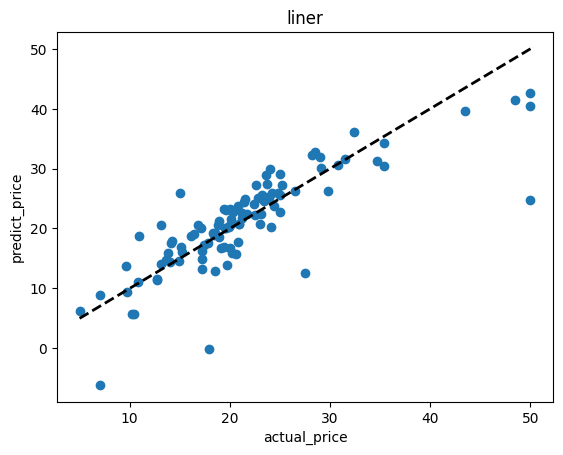

In [28]:
#使用sklearn进行线性回归
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#from sklearn.datasets import load_boston
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
 
# 加载波士顿房屋数据集
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
target = raw_df.values[1::2, 2]
 
# 数据准备
X = data
y = target
 
# 将数据集划分为训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
 
# 创建线性回归模型实例
model = LinearRegression()
 
# 模型训练
model.fit(X_train, y_train)
 
# 模型预测
y_pred = model.predict(X_test)
 
# 计算均方误差
mse = np.mean((y_pred - y_test) ** 2)
print("均方误差：", mse)
 
# 结果可视化
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.xlabel('actual_price')
plt.ylabel('predict_price')
plt.title('liner')
plt.show()

theta1 = np.append(model.intercept_,model.coef_)
theta1 = theta1[:,np.newaxis]


In [8]:
#使用简单数据的 SGD
import numpy as np
theta =np.zeros_like(theta1)
alpha = 0.01  # 学习率
threshold = 0.0001  # 停止迭代的错误阈值
iterations = 150000  # 迭代次数
error=0##初始错误为0
x=np.array([[1,1],[1,2],[2,1],[2,3],[3,2],[4,1],[4,2],[4,3]])
y=np.array([[3,5,4,8,7,6,8,10]])
y=y.T
for i in range(iterations):
    y_hat=np.dot(x,theta)
    error=(1/2)*np.dot((y_hat-y).T,(y_hat-y))
    if error<=threshold:
        break
    theta+=alpha/2*(np.dot(x.T,(y-np.dot(x,theta))))
print('迭代次数：{0}'.format(i + 1), 'theta：', theta, 'error：{0}'.format(error))


迭代次数：185 theta： [[1.00326097]
 [1.99511771]] error：[[9.67819251e-05]]


In [31]:
import numpy as np
y = target[:,np.newaxis]
x = np.concatenate((np.ones_like(y),data),axis=1)
theta2 = np.linalg.inv(x.T@x)@x.T@y
np.hstack((theta1,theta2))

array([[ 3.02467510e+01,  3.64594884e+01],
       [-1.13055924e-01, -1.08011358e-01],
       [ 3.01104641e-02,  4.64204584e-02],
       [ 4.03807204e-02,  2.05586264e-02],
       [ 2.78443820e+00,  2.68673382e+00],
       [-1.72026334e+01, -1.77666112e+01],
       [ 4.43883520e+00,  3.80986521e+00],
       [-6.29636221e-03,  6.92224640e-04],
       [-1.44786537e+00, -1.47556685e+00],
       [ 2.62429736e-01,  3.06049479e-01],
       [-1.06467863e-02, -1.23345939e-02],
       [-9.15456240e-01, -9.52747232e-01],
       [ 1.23513347e-02,  9.31168327e-03],
       [-5.08571424e-01, -5.24758378e-01]])

In [32]:
print((x@theta1-y).T@(x@theta1-y),(x@theta2-y).T@(x@theta2-y))

[[11220.82493875]] [[11078.78457795]]


In [26]:
#使用复杂数据 完成手工SGD；有点问题就是会偏向于 离群点。导致 逐渐差异值会越来越大
import numpy as np
y = target[:,np.newaxis]
x = np.concatenate((np.ones_like(y),data),axis=1)
# x = x.astype(np.float64)

m,n  = x.shape
theta3 = np.zeros(n)[:,np.newaxis]

alpha = 0.000001  # 学习率
threshold = 0.001  # 停止迭代的错误阈值
iterations = 15000  # 迭代次数
error=0 ##初始错误为0
avg_cost = []

for i in range(iterations): 
    for j in range(len(x)):
        error=(x[j:j+1]@theta3 - y[j]).ravel()[0]
        theta3 = theta3 - (alpha * error * x[j:j+1]).T
    y_hat = x@theta3
    avg_cost.append(((y_hat-y).T@(y_hat - y)).ravel()[0])
print('迭代次数：{0}'.format(i + 1), 'error：{0}'.format(error), 'theta：', theta3)

迭代次数：15000 error：8.034746930666989 theta： [[ 1.07749929e+00]
 [-8.88291143e-02]
 [ 1.87169929e-02]
 [-7.32690735e-02]
 [-1.02545574e+00]
 [ 5.80281015e-02]
 [ 5.19531168e+00]
 [-2.27150403e-02]
 [-5.85368526e-01]
 [ 3.15836172e-01]
 [-1.79295838e-02]
 [-1.35068789e-01]
 [ 1.77129595e-03]
 [-4.48461275e-01]]


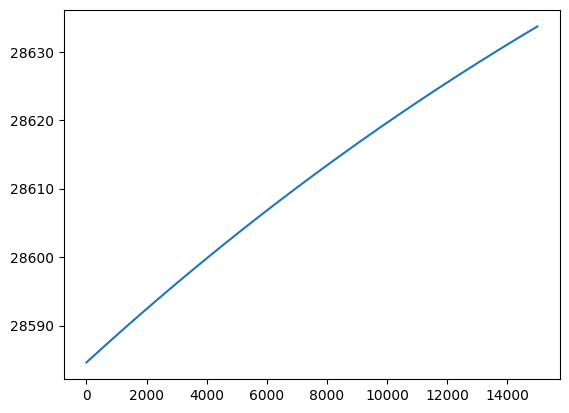

In [28]:
plt.plot(range(len(avg_cost)),avg_cost)

In [47]:
#复杂数据,使用向量方式求解 。好像误差比较大
import numpy as np
y = target[:,np.newaxis]
x = np.concatenate((np.ones_like(y),data),axis=1)
# x = x.astype(np.float64)

m,n  = x.shape
m1= n * 11
m2 = m // m1
# theta4 = np.zeros(n)[:,np.newaxis]
theta4 = []

alpha = 0.000001  # 学习率
threshold = 0.001  # 停止迭代的错误阈值
iterations = 15000  # 迭代次数
error=0 ##初始错误为0
avg_cost = []

for i in range(m2):
    j = m if i == m2 - 1 else (i+1) * m1
    t = x[i*m1:j,:]
    t1 = y[i*m1:j,:]
    print(j,t.shape)
    
    t = np.linalg.inv(t.T@t)@t.T@t1
    y_hat = x@t
    theta4.append(t[:,0])

    
    avg_cost.append(((y_hat-y).T@(y_hat - y)).ravel()[0])
theta4 = np.array(theta4)
t = np.average(theta4,axis=0)

# print('迭代次数：{0}'.format(i + 1), 'error：{0}'.format(error), 'theta：', t)

154 (154, 14)
308 (154, 14)
506 (198, 14)


In [57]:
np.hstack((theta1,theta2,np.average(theta4,axis=0)[:,np.newaxis]))

array([[ 3.02467510e+01,  3.64594884e+01,  7.71374354e+00],
       [-1.13055924e-01, -1.08011358e-01, -1.18922256e-01],
       [ 3.01104641e-02,  4.64204584e-02,  2.86678174e-02],
       [ 4.03807204e-02,  2.05586264e-02, -8.58859191e-02],
       [ 2.78443820e+00,  2.68673382e+00,  2.77846615e+00],
       [-1.72026334e+01, -1.77666112e+01, -1.13083859e+01],
       [ 4.43883520e+00,  3.80986521e+00,  5.45319364e+00],
       [-6.29636221e-03,  6.92224640e-04, -2.57332847e-02],
       [-1.44786537e+00, -1.47556685e+00, -1.09678987e+00],
       [ 2.62429736e-01,  3.06049479e-01, -1.32189407e-01],
       [-1.06467863e-02, -1.23345939e-02, -4.61528529e-03],
       [-9.15456240e-01, -9.52747232e-01, -2.91419278e-01],
       [ 1.23513347e-02,  9.31168327e-03,  1.09168299e-02],
       [-5.08571424e-01, -5.24758378e-01, -2.76241715e-01]])

In [64]:
t = x[0:14,:]
rank = np.linalg.matrix_rank(t)

In [68]:
import scipy
scipy.linalg.lu(t)
np.tril(t)

array([[1.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
       [1.0000e+00, 2.7310e-02, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
       [1.0000e+00, 2.7290e-02, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
       [1.0000e+00, 3.2370e-02, 0.0000e+00, 2.1800e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
       [1.0000e+00, 6.9050e-02, 0.0000e+00, 2.1800e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
       [1.0000e+00, 2.9850e-02, 0.0

In [71]:
t = np.arange(1,17).reshape(4,4)

In [73]:
np.tril(t)

array([[ 1,  0,  0,  0],
       [ 5,  6,  0,  0],
       [ 9, 10, 11,  0],
       [13, 14, 15, 16]])

In [91]:
x[j:j+1]@theta3 - y[j]

array([[-2.36797574]])

In [92]:
j = j+1

In [93]:
x[j-1:j]@theta3 - y[j-1]

array([[-2.36797574]])

In [94]:
(x@theta3 - y).T@(x@theta3 - y)

array([[21657.34151291]])

In [74]:
def gauss_elimination(matrix):
    """
    Perform Gaussian elimination to convert the input matrix to an upper triangular matrix,
    excluding the last two columns from elimination.
    
    Parameters:
    matrix (np.ndarray): The input matrix to be transformed.
    
    Returns:
    np.ndarray: The upper triangular matrix.
    """
    matrix = matrix.astype(float)
    m, n = matrix.shape
    
    for i in range(m):
        # Make the diagonal contain all 1's
        max_row = i
        for k in range(i + 1, m):
            if abs(matrix[k, i]) > abs(matrix[max_row, i]):
                max_row = k
        matrix[[i, max_row]] = matrix[[max_row, i]]
        
        # Make the elements below the pivot elements equal to zero, excluding the last two columns
        for k in range(i + 1, m):
            c = -matrix[k, i] / matrix[i, i]
            for j in range(i, n - 2):
                if i == j:
                    matrix[k, j] = 0
                else:
                    matrix[k, j] += c * matrix[i, j]
    
    return matrix



In [75]:
# Example usage
if __name__ == "__main__":
    arr = np.array([
        [2, 1, -1, -4],
        [-3, -1, 2, -1],
        [-2, 1, 2, -3]
    ])
    

    upper_triangular_matrix = gauss_elimination(arr)
    print(np.array(upper_triangular_matrix))
    print(np.linalg.inv(arr[:,0:3])@arr[:,-2:-1])

[[-3.         -1.          2.         -1.        ]
 [ 0.          1.66666667  2.         -3.        ]
 [ 0.          0.         -1.         -4.        ]]
[[-1.33226763e-15]
 [ 4.44089210e-16]
 [ 1.00000000e+00]]


In [81]:

arr[[2,0]] = arr[[0,2]]
arr

array([[-2,  1,  2, -3],
       [-3, -1,  2, -1],
       [ 2,  1, -1, -4]])

In [79]:
arr

array([[ 2,  1, -1, -4],
       [-3, -1,  2, -1],
       [-2,  1,  2, -3]])